# YouTube Trending Indonesia - Mencari Video Terpopuler

Dataset: **Indonesia Trending YouTube Video Statistics** (video yang masuk daftar trending Indonesia, Oktober 2020 - Januari 2021).

Alur notebook:
1. **Data Loading** ke `df_all`
2. **Hapus duplikat dan data kosong**, lalu ringkas menjadi **satu baris per video**
3. **Ranking video paling banyak views / trending**
4. **Split** menjadi `train_raw` dan `test_raw`
5. **Data Cleaning** menjadi `train_clean` dan `test_clean`
6. **Exploratory Data Analysis (EDA)** pada `train_clean`
7. **Modelling** (KNN dan pembanding Random Forest) untuk memprediksi video **populer**

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Data Loading

> File ini berisi kolom `description` yang memuat karakter baris baru di dalam teks, sehingga `pd.read_csv()` bawaan gagal membaca (error *Buffer overflow*). Solusinya memakai `lineterminator="\n"`.
>
> File CSV harus berada di **folder yang sama dengan notebook ini**. Nama file boleh memakai spasi atau garis bawah (`_`), keduanya dicoba otomatis. Di Google Colab, upload CSV ke sesi Colab.

In [2]:
import glob
import os

kandidat = [
    "Indonesia_Trending_YouTube_Video_Statistics.csv",
    "Indonesia Trending YouTube Video Statistics.csv",
    "/content/Indonesia_Trending_YouTube_Video_Statistics.csv",   # fallback Google Colab
] + glob.glob("*Indonesia*Trending*YouTube*.csv")

path_csv = next((p for p in kandidat if os.path.exists(p)), None)
if path_csv is None:
    raise FileNotFoundError("File CSV YouTube tidak ditemukan. Taruh file CSV di folder yang sama dengan notebook ini. "
                            f"Folder kerja saat ini: {os.getcwd()}")

df_all = pd.read_csv(path_csv, lineterminator="\n")
print("Membaca file:", path_csv)
df_all.head()

Membaca file: Indonesia Trending YouTube Video Statistics.csv


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description
0,3p7s7Rjh4fg,NCT U 엔시티 유 'From Home' MV,2020-10-19T09:00:15Z,UCEf_Bc-KVd7onSeifS3py9g,SMTOWN,10,20.24.10,[none],19747976,1319561,10648,281951,https://i.ytimg.com/vi/3p7s7Rjh4fg/default.jpg,False,False,NCT's 2nd album NCT - The 2nd Album RESONANCE ...
1,6ldgr3RRLVc,HARTA TAHTA CHEF RENATTA - ARNOLD POE,2020-10-19T08:30:11Z,UCr5k1iu1hF_01O1AD1JzcFA,Arnold Poernomo,24,20.24.10,Arnold Poernomo|Chef Arnold|Cooking|Master Che...,5756278,296553,4942,25969,https://i.ytimg.com/vi/6ldgr3RRLVc/default.jpg,False,False,kalo kemarin kita sudah ngobrol bareng Juri Ma...
2,5gLe94rL77Y,AYU TING TING - TATITUT (OFFICIAL MUSIC VIDEO),2020-10-21T03:00:10Z,UCxNTGZ-mmMLJvtD_DpuoEIw,Swara Bintang,24,20.24.10,Swara Bintang|Swara Bintang Indonesia|dangdut|...,1449507,102204,6947,49984,https://i.ytimg.com/vi/5gLe94rL77Y/default.jpg,False,False,Setelah sebelumnya merilis single Cemburu Mant...
3,UB4FzllQCyc,SEVENTEEN (세븐틴) 'HOME;RUN' Official MV,2020-10-19T09:00:00Z,UC3IZKseVpdzPSBaWxBxundA,Big Hit Labels,10,20.24.10,에스쿱스|정한|조슈아|준|호시|원우|우지|디에잇|민규|도겸|승관|버논|디노|SCOU...,18318661,1173051,10288,296560,https://i.ytimg.com/vi/UB4FzllQCyc/default.jpg,False,False,SEVENTEEN (세븐틴) 'HOME;RUN' Official MV세븐틴의 이번 ...
4,jRn6b7585es,TWICE I CAN'T STOP ME M/V Platform Teaser,2020-10-22T11:59:52Z,UCaO6TYtlC8U5ttz62hTrZgg,JYP Entertainment,10,20.24.10,TWICE|트와이스|eyeswideopen|I cant stop me|icantst...,7170494,722251,14022,110220,https://i.ytimg.com/vi/jRn6b7585es/default.jpg,False,False,TWICE I CAN'T STOP ME M/V Platform TeaserPre-S...


In [3]:
print("Jumlah baris :", df_all.shape[0])
print("Jumlah kolom :", df_all.shape[1])
df_all.info()

Jumlah baris : 10921
Jumlah kolom : 16
<class 'pandas.DataFrame'>
RangeIndex: 10921 entries, 0 to 10920
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   video_id           10921 non-null  str  
 1   title              10921 non-null  str  
 2   publishedAt        10921 non-null  str  
 3   channelId          10921 non-null  str  
 4   channelTitle       10921 non-null  str  
 5   categoryId         10921 non-null  int64
 6   trending_date      10921 non-null  str  
 7   tags               10921 non-null  str  
 8   view_count         10921 non-null  int64
 9   likes              10921 non-null  int64
 10  dislikes           10921 non-null  int64
 11  comment_count      10921 non-null  int64
 12  thumbnail_link     10921 non-null  str  
 13  comments_disabled  10921 non-null  bool 
 14  ratings_disabled   10921 non-null  bool 
 15  description        10792 non-null  str  
dtypes: bool(2), int64(5), str(9)
m

## 3. Hapus Duplikat dan Data Kosong

Data ini berbentuk **harian**: satu video bisa muncul berkali-kali pada tanggal trending yang berbeda (views-nya naik tiap hari). Penanganannya:

1. Buang baris yang **identik sepenuhnya** (`drop_duplicates()`).
2. Buang baris yang kolom pentingnya kosong.
3. Satu video pada satu tanggal hanya boleh muncul sekali.
4. **Ringkas menjadi satu baris per video** (`video_id`).

Langkah 4 penting: kalau video yang sama muncul di train **dan** test, model hanya mengenali video yang sama (data leakage), sama seperti kasus duplikat pada dataset Heart Disease.

In [4]:
print("Baris awal             :", len(df_all))
print("Duplikat baris penuh   :", df_all.duplicated().sum())
print()
print("Kolom yang punya missing value:")
kosong = df_all.isnull().sum()
print(kosong[kosong > 0])

Baris awal             : 10921
Duplikat baris penuh   : 2

Kolom yang punya missing value:
description    129
dtype: int64


In [5]:
df_harian = df_all.drop_duplicates().copy()

kolom_penting = ["video_id", "publishedAt", "trending_date", "categoryId",
                 "view_count", "likes", "dislikes", "comment_count"]
df_harian = df_harian.dropna(subset=kolom_penting)

# trending_date berformat yy.dd.mm (contoh 20.24.10 = 24 Oktober 2020)
df_harian["trending_dt"] = pd.to_datetime(df_harian["trending_date"], format="%y.%d.%m")
df_harian["published_dt"] = pd.to_datetime(df_harian["publishedAt"], utc=True).dt.tz_localize(None)

# satu video pada satu tanggal trending hanya satu baris
df_harian = (df_harian.sort_values(["video_id", "trending_dt", "view_count"])
                      .drop_duplicates(["video_id", "trending_dt"], keep="last")
                      .reset_index(drop=True))

print("Baris harian setelah dibersihkan:", len(df_harian))
print("Jumlah video unik               :", df_harian["video_id"].nunique())

Baris harian setelah dibersihkan: 10919
Jumlah video unik               : 1297


### Ringkas menjadi satu baris per video

- **Fitur** diambil dari **hari pertama** video masuk trending (likes, dislikes, komentar, selisih hari rilis ke trending).
- **`peak_views`** = views tertinggi selama video berada di trending.
- **`hari_trending`** = berapa hari video bertahan di daftar trending.
- `description`, `thumbnail_link`, dan `channelId` dibuang karena tidak dipakai.

In [6]:
ringkas = df_harian.groupby("video_id").agg(
    peak_views=("view_count", "max"),
    hari_trending=("trending_dt", "nunique"),
).reset_index()

pertama = df_harian.drop_duplicates("video_id", keep="first")   # data terurut, jadi baris pertama = hari trending pertama
pertama = pertama[["video_id", "title", "channelTitle", "categoryId", "published_dt", "trending_dt",
                   "tags", "likes", "dislikes", "comment_count",
                   "comments_disabled", "ratings_disabled"]]

df_all = pertama.merge(ringkas, on="video_id").reset_index(drop=True)

print("df_all (satu baris per video):", df_all.shape)
df_all.head()

df_all (satu baris per video): (1297, 14)


,video_id,title,channelTitle,categoryId,published_dt,trending_dt,tags,likes,dislikes,comment_count,comments_disabled,ratings_disabled,peak_views,hari_trending
0,-0XJfocPNr8,IDE KOSTUM HALLOWEEN SERU DAN SUPER SERAM || D...,123 GO! BOYS Indonesian,24,2020-10-31 09:08:32,2020-11-02,DIY|kiathidup|tantangan|lucu|prank|cowok|123GO...,7249,724,583,False,False,4114760,20
1,-1yHyPAR4oQ,KAGET! BAYARAN NIKITA WILLY MAIN SINETRON! GIL...,Boy William,24,2020-11-27 07:00:00,2020-11-28,Dibalik Pintu|Di balik pintu nikita willy|Niki...,29053,345,2176,False,False,2457778,15
2,-5q5mZbe3V8,BTS (방탄소년단) 'Life Goes On' Official MV,Big Hit Labels,10,2020-11-20 04:58:11,2020-11-21,BIGHIT|빅히트|방탄소년단|BTS|BANGTAN|방탄,5224944,12581,2302498,False,False,187029956,22
3,-95zbPBxMfo,将军家的小娘子 💖 讓我吻一個，我就告訴你完美的計劃，瞞過皇帝 💖 中国电视剧,温柔一击,1,2020-11-03 12:48:02,2020-11-05,温柔一击|chinese television dramas|chinese tv dram...,1795,44,45,False,False,179995,2
4,-DAD8rQio30,[CONTOUR:BACKSTAGE] NCT DREAM EP.2 (360º VR),NCT DREAM,22,2020-12-30 11:00:00,2021-01-01,[none],52919,75,1408,False,False,408494,7


In [7]:
print("Duplikat video_id :", df_all["video_id"].duplicated().sum())
print("Missing value     :", df_all.isnull().sum().sum())

Duplikat video_id : 0
Missing value     : 0


## 4. Ranking: Video Paling Banyak Views dan Paling Lama Trending

Bagian ini bersifat **deskriptif** (mencari video nyata), jadi memakai seluruh `df_all`.

In [8]:
kategori_map = {1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music", 15: "Pets & Animals",
                17: "Sports", 19: "Travel & Events", 20: "Gaming", 22: "People & Blogs",
                23: "Comedy", 24: "Entertainment", 25: "News & Politics", 26: "Howto & Style",
                27: "Education", 28: "Science & Technology", 29: "Nonprofits & Activism"}

df_all["kategori"] = df_all["categoryId"].astype(int).map(kategori_map)

top_views = (df_all.nlargest(10, "peak_views")
             [["title", "channelTitle", "kategori", "peak_views", "hari_trending"]]
             .reset_index(drop=True))
top_views.index = top_views.index + 1
top_views

,title,channelTitle,kategori,peak_views,hari_trending
1,BLACKPINK – ‘Lovesick Girls’ M/V,BLACKPINK,Music,201852792,3
2,BTS (방탄소년단) 'Life Goes On' Official MV,Big Hit Labels,Music,187029956,22
3,TWICE I CAN'T STOP ME M/V,JYP Entertainment,Music,120027271,21
4,NCT U 엔시티 유 'Make A Wish (Birthday Song)' MV,SMTOWN,Music,88167898,11
5,Ariana Grande - positions (official video),ArianaGrandeVevo,Music,76568368,17
6,aespa 에스파 'Black Mamba' MV,SMTOWN,Music,65220193,16
7,BLACKPINK - 'Lovesick Girls' DANCE PRACTICE VIDEO,BLACKPINK,Music,60013190,7
8,Billie Eilish - Therefore I Am (Official Music...,BillieEilishVEVO,Music,58629555,15
9,NCT U 엔시티 유 '90's Love' MV,SMTOWN,Music,55905517,19
10,Apple Event — October 13,Apple,Science & Technology,53887985,2


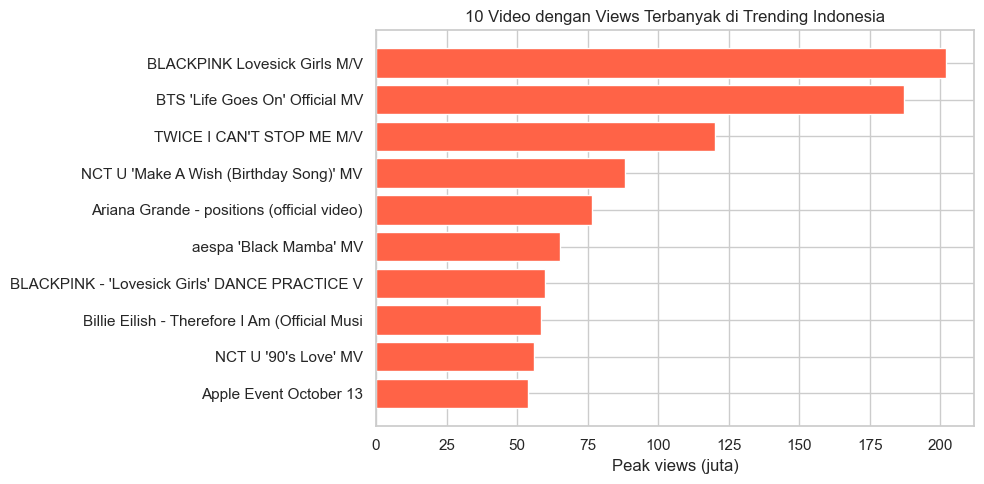

In [9]:
import re

def label_ascii(t):
    t = re.sub(r"[^\x00-\x7F]+", "", t)          # buang huruf non-latin agar tampil di grafik
    t = re.sub(r"\(\s*\)", "", t)                # buang tanda kurung kosong
    return re.sub(r"\s+", " ", t).strip()[:45]

plt.figure(figsize=(10, 5))
data_plot = top_views.iloc[::-1]
plt.barh(data_plot["title"].apply(label_ascii), data_plot["peak_views"] / 1e6, color="tomato")
plt.xlabel("Peak views (juta)")
plt.title("10 Video dengan Views Terbanyak di Trending Indonesia")
plt.tight_layout()
plt.show()

### Video yang paling lama bertahan di trending

In [10]:
top_lama = (df_all.nlargest(10, "hari_trending")
            [["title", "channelTitle", "kategori", "peak_views", "hari_trending"]]
            .reset_index(drop=True))
top_lama.index = top_lama.index + 1
top_lama

,title,channelTitle,kategori,peak_views,hari_trending
1,TANTANGAN MAKANAN ASLI vs MAKANAN COKLAT || Ha...,RATATA Indonesian,Entertainment,32891569,26
2,BTS (방탄소년단) 'Life Goes On' Official MV,Big Hit Labels,Music,187029956,22
3,HAPPY ASMARA - L D R | Layang Dongo Restu | (O...,FORTUNA ENTERPRISE,Music,5311306,22
4,UJI HACK & TRIK VIRAL TikTok DI KEHIDUPAN NYAT...,RATATA Indonesian,Entertainment,14180795,22
5,Denny Caknan feat. Happy Asmara - AKU IKLAS by...,DENNY CAKNAN,Music,5252784,22
6,BAKU HANTAM THE DARK CHEF INDONESIA! PART 2,Arnold Poernomo,Entertainment,11778286,22
7,Jessi(제시) & Jackson(GOT7) - NUNU NANA(눈누난나) [2...,KBS World,Entertainment,28649678,22
8,Bahagia! Tak Sadar Leslar Meneteskan Air Mata ...,Indosiar,Entertainment,12317057,22
9,FPI Benarkan Rekaman Suara yang Beredar: Mana ...,KOMPASTV,News & Politics,7796207,21
10,Cuek X Mantra Cinta (KERONCONG) - Live Session...,James Adam,Music,6078122,21


### "Trending banget": views di atas 10 juta, diurutkan dari yang paling lama trending

In [11]:
trending_banget = (df_all[df_all["peak_views"] >= 10_000_000]
                   .nlargest(10, "hari_trending")
                   [["title", "channelTitle", "kategori", "peak_views", "hari_trending"]]
                   .reset_index(drop=True))
trending_banget.index = trending_banget.index + 1

print("Jumlah video dengan peak views >= 10 juta:", (df_all["peak_views"] >= 10_000_000).sum())
trending_banget

Jumlah video dengan peak views >= 10 juta: 87


,title,channelTitle,kategori,peak_views,hari_trending
1,TANTANGAN MAKANAN ASLI vs MAKANAN COKLAT || Ha...,RATATA Indonesian,Entertainment,32891569,26
2,BTS (방탄소년단) 'Life Goes On' Official MV,Big Hit Labels,Music,187029956,22
3,UJI HACK & TRIK VIRAL TikTok DI KEHIDUPAN NYAT...,RATATA Indonesian,Entertainment,14180795,22
4,BAKU HANTAM THE DARK CHEF INDONESIA! PART 2,Arnold Poernomo,Entertainment,11778286,22
5,Jessi(제시) & Jackson(GOT7) - NUNU NANA(눈누난나) [2...,KBS World,Entertainment,28649678,22
6,Bahagia! Tak Sadar Leslar Meneteskan Air Mata ...,Indosiar,Entertainment,12317057,22
7,TRIK MAKANAN GENIUS UNTUK HIDANGAN LEZAT! || I...,123 GO LIKE! Indonesian,Entertainment,14025256,21
8,TWICE I CAN'T STOP ME M/V,JYP Entertainment,Music,120027271,21
9,"MALIH, PESAN PEDAS TUK ADE LONDOK - Deddy Corb...",Deddy Corbuzier,Entertainment,11434075,21
10,TREASURE - ‘음 (MMM)’ M/V,TREASURE (트레저),Entertainment,22205706,21


### Channel dengan video trending terbanyak

In [12]:
top_channel = (df_all.groupby("channelTitle")
               .agg(jumlah_video=("video_id", "count"), total_peak_views=("peak_views", "sum"))
               .sort_values("jumlah_video", ascending=False)
               .head(10))
top_channel

,jumlah_video,total_peak_views
channelTitle,,
Indonesian Idol,21,72599896
Cumicumi,13,21330920
TRANS7 OFFICIAL,13,18465385
TREASURE (트레저),13,40494023
SMTOWN,13,375936073
metrotvnews,12,17900671
Official iNews,12,21006241
tvOneNews,11,31187004
Serie A,11,63434304


## 5. Menentukan Target: Video Populer

Target klasifikasi dibuat dari `peak_views`:

- **`populer = 1`** jika `peak_views >= 3.000.000`
- **`populer = 0`** jika kurang dari itu

Ambang 3 juta adalah angka tetap (bukan dihitung dari data train atau test), sehingga tidak menimbulkan data leakage.

In [13]:
AMBANG_POPULER = 3_000_000
df_all["populer"] = (df_all["peak_views"] >= AMBANG_POPULER).astype(int)

print(df_all["populer"].value_counts())
print((df_all["populer"].value_counts(normalize=True) * 100).round(1))

populer
0    966
1    331
Name: count, dtype: int64
populer
0    74.5
1    25.5
Name: proportion, dtype: float64


## 6. Split: `train_raw` dan `test_raw`

Karena sudah satu baris per video, tidak ada video yang sama di train dan test. Parameter: `test_size=0.2`, `random_state=42`, `stratify` pada target.

In [14]:
from sklearn.model_selection import train_test_split

train_raw, test_raw = train_test_split(
    df_all, test_size=0.2, random_state=42, stratify=df_all["populer"]
)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)

print("df_all    :", df_all.shape)
print("train_raw :", train_raw.shape, f"({len(train_raw)/len(df_all)*100:.1f}%)")
print("test_raw  :", test_raw.shape, f"({len(test_raw)/len(df_all)*100:.1f}%)")
print()
print("Distribusi populer train_raw:", train_raw["populer"].value_counts().to_dict())
print("Distribusi populer test_raw :", test_raw["populer"].value_counts().to_dict())
print("Video yang sama di train dan test:", len(set(train_raw["video_id"]) & set(test_raw["video_id"])))

df_all    : (1297, 16)
train_raw : (1037, 16) (80.0%)
test_raw  : (260, 16) (20.0%)

Distribusi populer train_raw: {0: 772, 1: 265}
Distribusi populer test_raw : {0: 194, 1: 66}
Video yang sama di train dan test: 0


## 7. Data Cleaning

Hasil disimpan di `train_clean` dan `test_clean`. Langkahnya:

1. **Rekayasa fitur dasar** (per baris, tidak memakai statistik data lain): jumlah tag, panjang judul, jam dan hari rilis, selisih hari dari rilis ke trending, mengubah `True/False` menjadi 1/0.
2. **Cek missing value dan nilai tidak valid.**
3. **Cek outlier (IQR)**, batas dihitung dari data train. Outlier **tidak dihapus**: views, likes, dan komentar yang sangat besar adalah video viral, yaitu justru yang ingin dicari.
4. **Transformasi `log1p`** pada likes, dislikes, dan komentar yang sangat miring ke kanan.

In [15]:
def siapkan(d):
    d = d.copy()
    d["jumlah_tags"] = d["tags"].apply(lambda t: 0 if (pd.isnull(t) or t == "[none]") else len(t.split("|")))
    d["panjang_judul"] = d["title"].str.len()
    d["publish_hour"] = d["published_dt"].dt.hour
    d["publish_dayofweek"] = d["published_dt"].dt.dayofweek
    d["days_to_trending"] = (d["trending_dt"] - d["published_dt"].dt.normalize()).dt.days
    d["comments_disabled"] = d["comments_disabled"].astype(int)
    d["ratings_disabled"] = d["ratings_disabled"].astype(int)
    d["categoryId"] = d["categoryId"].astype(int)
    return d

train_clean = siapkan(train_raw)
test_clean = siapkan(test_raw)

In [16]:
print("Missing train_clean:", train_clean.isnull().sum().sum())
print("Missing test_clean :", test_clean.isnull().sum().sum())
print()
print("Nilai tidak valid (negatif / nol) pada train_clean:")
for kolom in ["likes", "dislikes", "comment_count", "days_to_trending", "panjang_judul"]:
    print(f"  {kolom}: negatif = {(train_clean[kolom] < 0).sum()}")
print("  days_to_trending < 0:", (train_clean["days_to_trending"] < 0).sum())

Missing train_clean: 0
Missing test_clean : 0

Nilai tidak valid (negatif / nol) pada train_clean:
  likes: negatif = 0
  dislikes: negatif = 0
  comment_count: negatif = 0
  days_to_trending: negatif = 0
  panjang_judul: negatif = 0
  days_to_trending < 0: 0


### Cek outlier (batas IQR dari train, tidak dihapus)

In [17]:
kolom_cek = ["likes", "dislikes", "comment_count", "days_to_trending", "jumlah_tags", "panjang_judul"]

Q1 = train_clean[kolom_cek].quantile(0.25)
Q3 = train_clean[kolom_cek].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

pd.DataFrame({
    "batas_bawah": batas_bawah.round(1),
    "batas_atas": batas_atas.round(1),
    "outlier_train": [((train_clean[c] < batas_bawah[c]) | (train_clean[c] > batas_atas[c])).sum() for c in kolom_cek],
    "outlier_test": [((test_clean[c] < batas_bawah[c]) | (test_clean[c] > batas_atas[c])).sum() for c in kolom_cek],
})

,batas_bawah,batas_atas,outlier_train,outlier_test
likes,-83802.0,158294.0,149,35
dislikes,-1684.5,3367.5,122,27
comment_count,-8741.5,17038.5,123,26
days_to_trending,0.5,4.5,142,39
jumlah_tags,-21.5,54.5,12,1
panjang_judul,-9.5,138.5,0,0


In [18]:
print("Skewness sebelum log1p (train_clean):")
print(train_clean[["likes", "dislikes", "comment_count"]].skew().round(2))

for d in (train_clean, test_clean):
    d["likes_log"] = np.log1p(d["likes"])
    d["dislikes_log"] = np.log1p(d["dislikes"])
    d["comment_log"] = np.log1p(d["comment_count"])

print()
print("Skewness sesudah log1p (train_clean):")
print(train_clean[["likes_log", "dislikes_log", "comment_log"]].skew().round(2))

Skewness sebelum log1p (train_clean):
likes            12.31
dislikes         17.88
comment_count    17.85
dtype: float64

Skewness sesudah log1p (train_clean):
likes_log      -0.97
dislikes_log   -0.36
comment_log    -0.36
dtype: float64


In [19]:
fitur_numerik = ["likes_log", "dislikes_log", "comment_log", "days_to_trending",
                 "publish_hour", "publish_dayofweek", "jumlah_tags", "panjang_judul"]
fitur_biner = ["comments_disabled", "ratings_disabled"]
fitur_kategori = ["categoryId"]
fitur_model = fitur_numerik + fitur_biner + fitur_kategori

print("Duplikat video_id train_clean:", train_clean["video_id"].duplicated().sum())
print("train_clean:", train_clean.shape, "| test_clean:", test_clean.shape)
print("Jumlah fitur untuk model:", len(fitur_model))
train_clean[["title", "kategori"] + fitur_model + ["peak_views", "hari_trending", "populer"]].head()

Duplikat video_id train_clean: 0
train_clean: (1037, 24) | test_clean: (260, 24)
Jumlah fitur untuk model: 11


,title,kategori,likes_log,dislikes_log,comment_log,days_to_trending,publish_hour,publish_dayofweek,jumlah_tags,panjang_judul,comments_disabled,ratings_disabled,categoryId,peak_views,hari_trending,populer
0,ADAM - IZINKAN AKU #MENGHALALKANMU,Music,12.044835,7.135687,10.296003,14,3,5,0,34,0,0,10,1704404,4,0
1,"Terkuak Motif Rekam dan Sosok MYD, Pemeran Pri...",Entertainment,5.631212,3.988984,4.912655,2,13,1,26,70,0,0,24,186292,9,0
2,EKSKLUSIF!!! Anggota FPI Amankan Terduga Anggo...,News & Politics,8.236421,5.953243,7.676474,2,11,5,16,98,0,0,25,390745,9,0
3,"BOLOT, GUE GAK KENAL COPID‼️- Deddy Corbuzier ...",Entertainment,11.900193,7.346010,9.959632,5,3,3,7,53,0,0,24,3149012,1,1
4,Dory Harsa - Demi Kowe [OFFICIAL],Music,9.577965,6.779922,9.197964,5,10,3,23,33,0,0,10,335238,3,0


## 8. Exploratory Data Analysis (EDA)

EDA dilakukan pada **`train_clean`** saja.

### 8.1 Statistik Deskriptif

In [20]:
train_clean[["peak_views", "hari_trending", "likes", "dislikes", "comment_count",
             "days_to_trending", "jumlah_tags", "panjang_judul"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
peak_views,1037.0,3919484.0,11585405.3,21418.0,650495.0,1417380.0,3035275.0,201852792.0
hari_trending,1037.0,8.4,5.6,1.0,3.0,8.0,13.0,26.0
likes,1037.0,124089.7,464477.1,0.0,6984.0,19730.0,67508.0,10008947.0
dislikes,1037.0,1873.7,6807.3,0.0,210.0,516.0,1473.0,176316.0
comment_count,1037.0,16194.7,96218.9,0.0,926.0,2529.0,7371.0,2302498.0
days_to_trending,1037.0,3.0,3.1,1.0,2.0,2.0,3.0,26.0
jumlah_tags,1037.0,17.5,12.9,0.0,7.0,16.0,26.0,64.0
panjang_judul,1037.0,63.9,23.3,2.0,46.0,65.0,83.0,100.0


### 8.2 Distribusi Target dan Peak Views

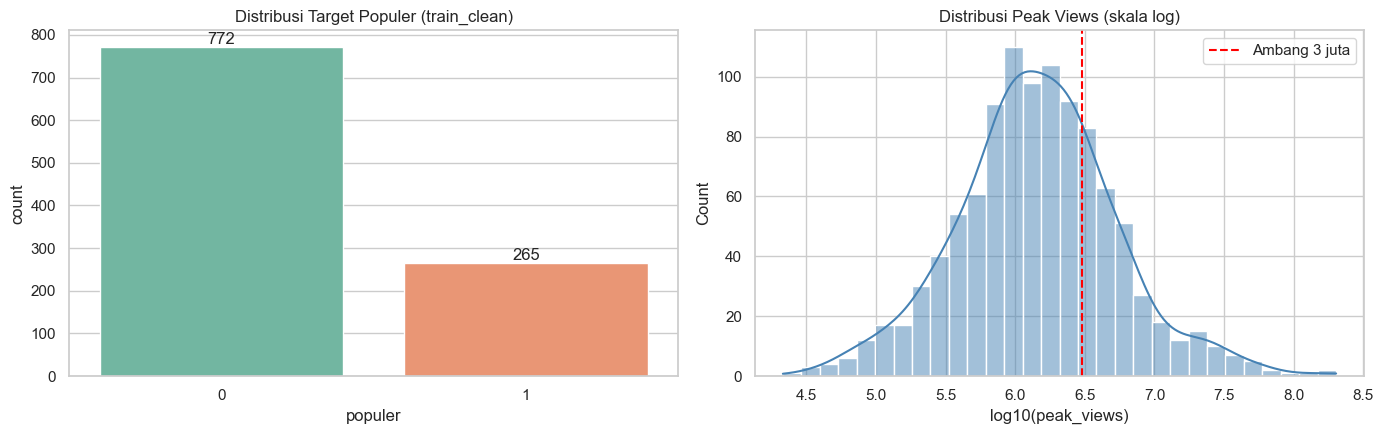

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = sns.countplot(x="populer", data=train_clean, ax=axes[0], palette="Set2", hue="populer", legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[0].set_title("Distribusi Target Populer (train_clean)")

sns.histplot(np.log10(train_clean["peak_views"]), bins=30, kde=True, ax=axes[1], color="steelblue")
axes[1].axvline(np.log10(AMBANG_POPULER), color="red", linestyle="--", label="Ambang 3 juta")
axes[1].set_xlabel("log10(peak_views)")
axes[1].set_title("Distribusi Peak Views (skala log)")
axes[1].legend()
plt.tight_layout()
plt.show()

### 8.3 Fitur Numerik terhadap Populer

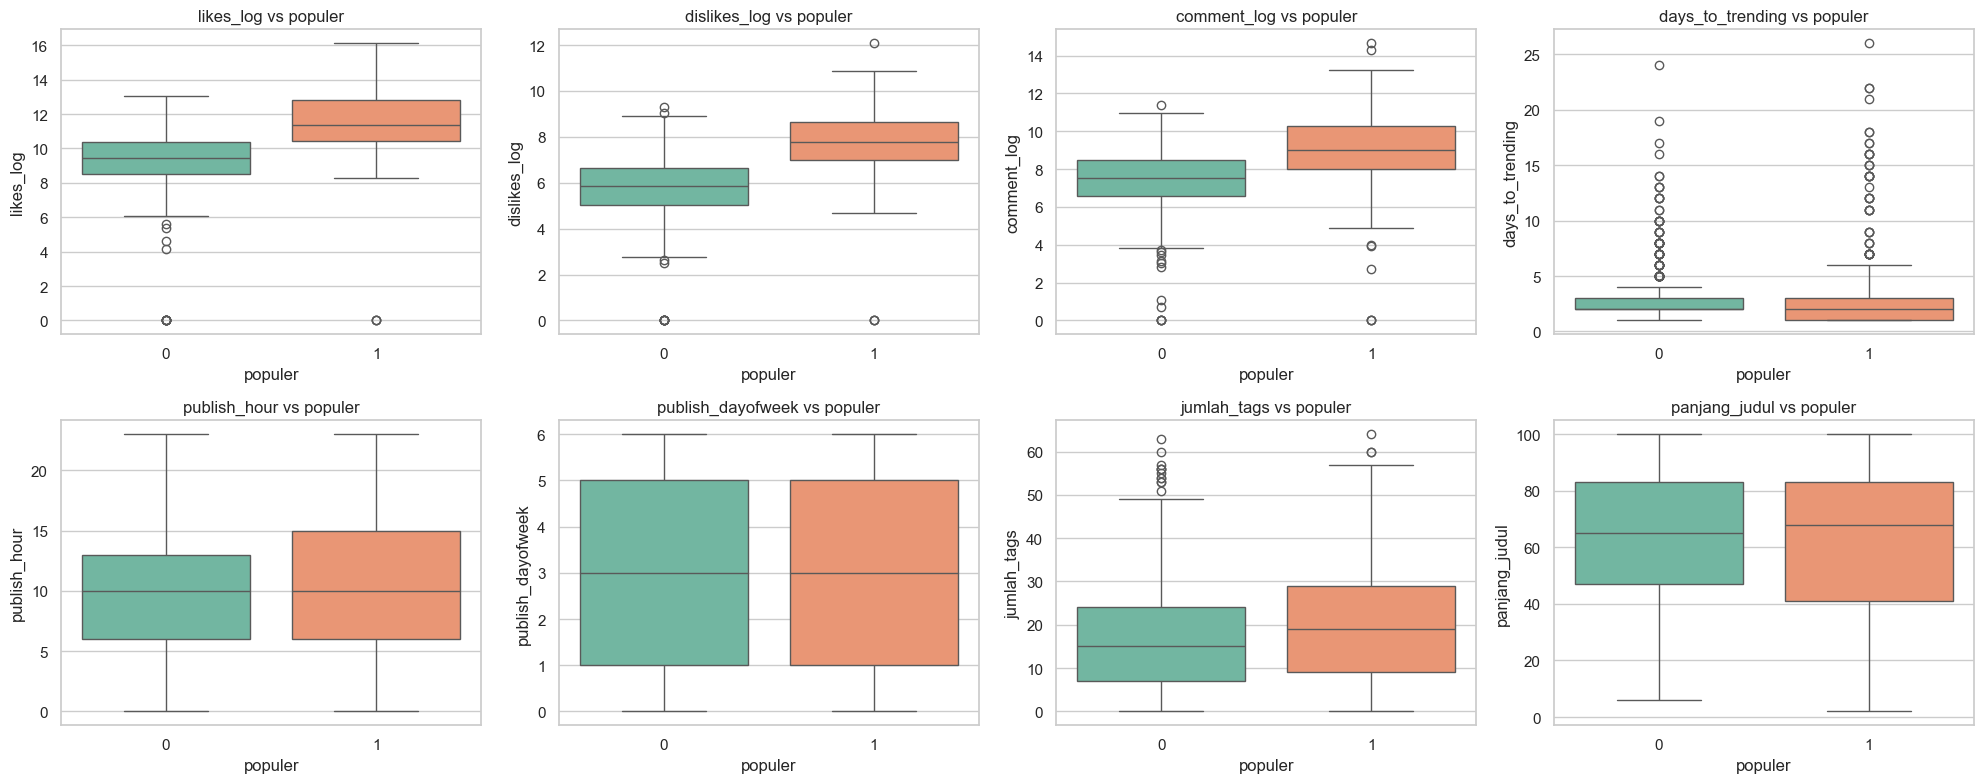

,likes_log,dislikes_log,comment_log,days_to_trending,publish_hour,publish_dayofweek,jumlah_tags,panjang_judul
populer,,,,,,,,
0,9.42,5.80,7.43,2.67,9.95,3.07,16.62,64.43
1,11.49,7.74,9.04,3.80,10.65,2.75,19.99,62.44


In [22]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, kolom in zip(axes.flatten(), fitur_numerik):
    sns.boxplot(x="populer", y=kolom, data=train_clean, ax=ax, palette="Set2", hue="populer", legend=False)
    ax.set_title(f"{kolom} vs populer")
plt.tight_layout()
plt.show()

train_clean.groupby("populer")[fitur_numerik].mean().round(2)

### 8.4 Kategori Video

In [23]:
ringkas_kat = (train_clean.groupby("kategori")
               .agg(jumlah=("video_id", "count"),
                    persen_populer=("populer", lambda s: round(s.mean() * 100, 1)),
                    median_peak_views=("peak_views", "median"))
               .sort_values("persen_populer", ascending=False))
ringkas_kat

,jumlah,persen_populer,median_peak_views
kategori,,,
Howto & Style,20,55.0,4673240.0
Science & Technology,9,44.4,2673420.0
Music,218,37.2,2004058.5
Entertainment,355,29.0,1722182.0
Sports,99,24.2,1606521.0
Gaming,18,22.2,930982.0
News & Politics,145,16.6,1090350.0
Film & Animation,20,10.0,524879.5
People & Blogs,81,9.9,843601.0


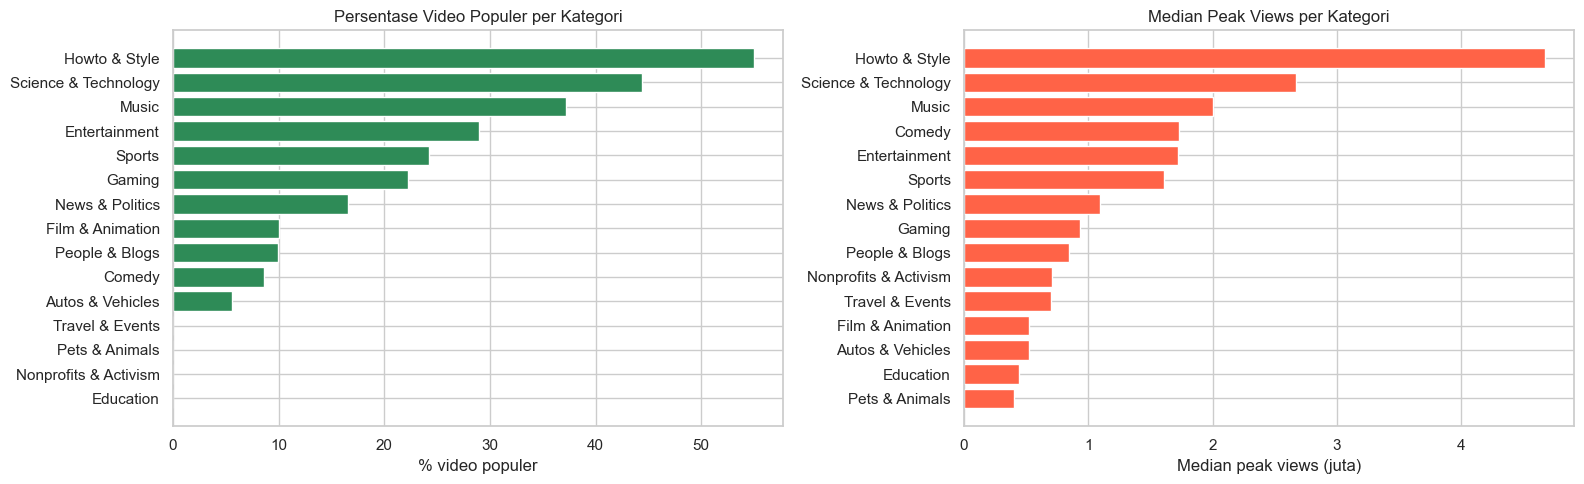

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

urut = ringkas_kat.sort_values("persen_populer").index
axes[0].barh(urut, ringkas_kat.loc[urut, "persen_populer"], color="seagreen")
axes[0].set_xlabel("% video populer")
axes[0].set_title("Persentase Video Populer per Kategori")

urut2 = ringkas_kat.sort_values("median_peak_views").index
axes[1].barh(urut2, ringkas_kat.loc[urut2, "median_peak_views"] / 1e6, color="tomato")
axes[1].set_xlabel("Median peak views (juta)")
axes[1].set_title("Median Peak Views per Kategori")
plt.tight_layout()
plt.show()

### 8.5 Lama Trending dan Peak Views

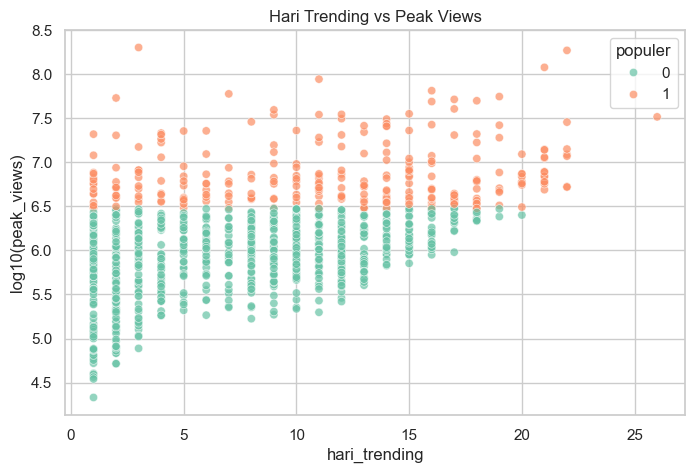

Korelasi hari_trending dengan log10(peak_views): 0.474


In [25]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="hari_trending", y=np.log10(train_clean["peak_views"]), hue="populer",
                data=train_clean, palette="Set2", alpha=0.7)
plt.ylabel("log10(peak_views)")
plt.title("Hari Trending vs Peak Views")
plt.show()

print("Korelasi hari_trending dengan log10(peak_views):",
      round(train_clean["hari_trending"].corr(np.log10(train_clean["peak_views"])), 3))

### 8.6 Korelasi Antar Variabel

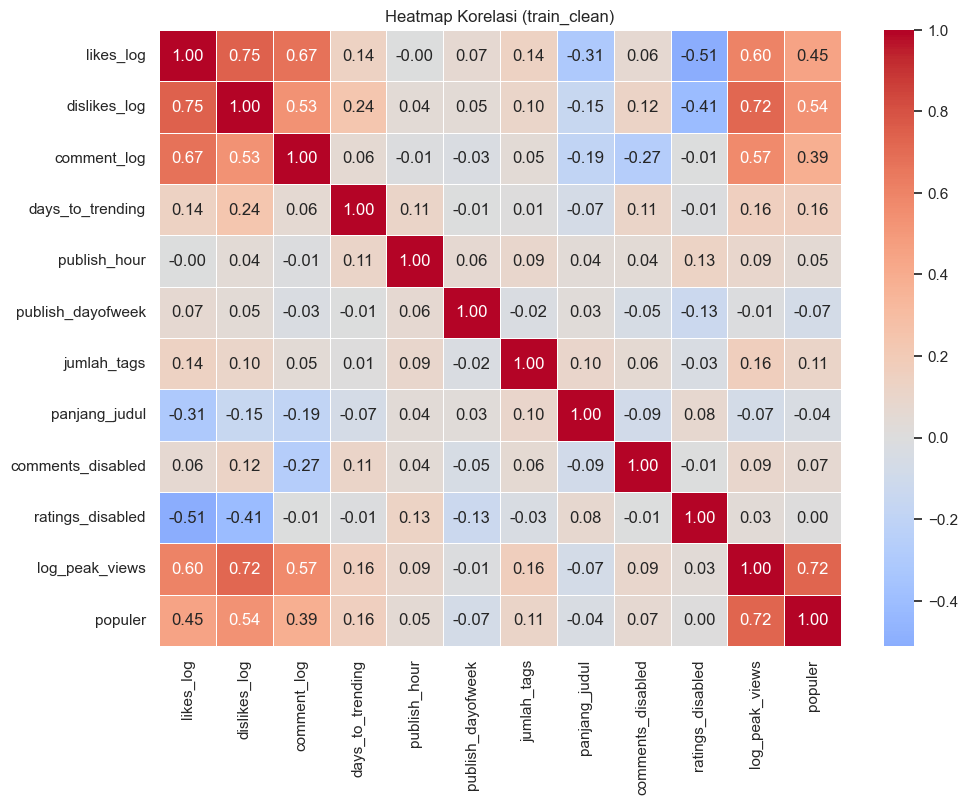

In [26]:
data_korelasi = train_clean[fitur_numerik + fitur_biner].copy()
data_korelasi["log_peak_views"] = np.log10(train_clean["peak_views"])
data_korelasi["populer"] = train_clean["populer"]

plt.figure(figsize=(11, 8))
sns.heatmap(data_korelasi.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Heatmap Korelasi (train_clean)")
plt.show()

In [27]:
korelasi_target = data_korelasi.corr()["populer"].drop("populer").sort_values()
korelasi_target.sort_values(ascending=False).round(3)

log_peak_views       0.725
dislikes_log         0.536
likes_log            0.449
comment_log          0.387
days_to_trending     0.160
jumlah_tags          0.114
comments_disabled    0.071
publish_hour         0.054
ratings_disabled     0.004
panjang_judul       -0.037
publish_dayofweek   -0.069
Name: populer, dtype: float64

### 8.7 Kesimpulan EDA

1. **Target tidak seimbang ringan.** Pada `train_clean`, 265 dari 1.037 video (25,5%) berstatus populer (peak views >= 3 juta). Pembagian train dan test sudah memakai `stratify`, jadi proporsinya sama.
2. **Views sangat miring ke kanan.** Median `peak_views` 1,42 juta, rata-rata 3,92 juta, dan maksimum 201,9 juta. Karena itu grafik memakai skala log.
3. **Fitur engagement paling berhubungan dengan popularitas** (korelasi dengan `populer`): `dislikes_log` 0,54, `likes_log` 0,45, dan `comment_log` 0,39. Rata-rata `likes_log` pada video populer 11,49 berbanding 9,42 pada yang tidak populer.
4. **Fitur waktu dan judul lemah:** `days_to_trending` 0,16, `jumlah_tags` 0,11, `publish_hour` 0,05, `publish_dayofweek` -0,07, `panjang_judul` -0,04.
5. **Kategori.** Persentase video populer tertinggi: Howto & Style 55,0% (hanya 20 video) dan Science & Technology 44,4% (hanya 9 video). Kategori dengan video terbanyak: Music (218 video, 37,2% populer) dan Entertainment (355 video, 29,0%). Yang rendah: Comedy 8,6%, People & Blogs 9,9%, dan News & Politics 16,6%. Kategori dengan sampel kecil kurang stabil.
6. **Lama trending berhubungan sedang dengan views.** Korelasi `hari_trending` dengan log10(`peak_views`) 0,47. Video yang bertahan lama di trending cenderung punya views besar. Fitur ini tidak dipakai di model karena baru diketahui setelah video berhari-hari trending.
7. **Outlier dipertahankan.** Di train ada 149 outlier `likes`, 122 `dislikes`, dan 123 `comment_count` (metode IQR). Semuanya video viral yang justru dicari, sehingga tidak dihapus. Skewness `likes` turun dari 12,31 menjadi -0,97 setelah `log1p`.

## 9. Modelling

Tujuan: memprediksi apakah sebuah video akan **populer** (peak views >= 3 juta) dari data saat **pertama kali masuk trending**.

Model utama **KNN** (sesuai materi). `StandardScaler` untuk fitur numerik dan `OneHotEncoder` untuk `categoryId` dimasukkan ke dalam `Pipeline` + `ColumnTransformer`, sehingga hanya mempelajari data train pada setiap fold (tidak ada data leakage).

> `views` hari pertama sengaja **tidak dipakai** sebagai fitur, agar model belajar dari karakteristik dan engagement video, bukan sekadar menebak dari views.

### 9.1 Pisahkan Fitur dan Target

In [28]:
X_train = train_clean[fitur_model]
y_train = train_clean["populer"]
X_test = test_clean[fitur_model]
y_test = test_clean["populer"]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

X_train: (1037, 11) | y_train: (1037,)
X_test : (260, 11) | y_test : (260,)


### 9.2 Model Baseline KNN (k = 5)

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def buat_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), fitur_numerik + fitur_biner),
        ("cat", OneHotEncoder(handle_unknown="ignore"), fitur_kategori),
    ])

baseline = Pipeline([("pre", buat_preprocessor()), ("knn", KNeighborsClassifier(n_neighbors=5))])
baseline.fit(X_train, y_train)

print("Akurasi baseline (k=5) - train:", round(accuracy_score(y_train, baseline.predict(X_train)), 4))
print("Akurasi baseline (k=5) - test :", round(accuracy_score(y_test, baseline.predict(X_test)), 4))

Akurasi baseline (k=5) - train: 0.8891
Akurasi baseline (k=5) - test : 0.8192


### 9.3 Mencari k Optimal (Cross-Validation 5-fold)

k terbaik berdasarkan akurasi CV: 19
Akurasi CV pada k tersebut      : 0.8332


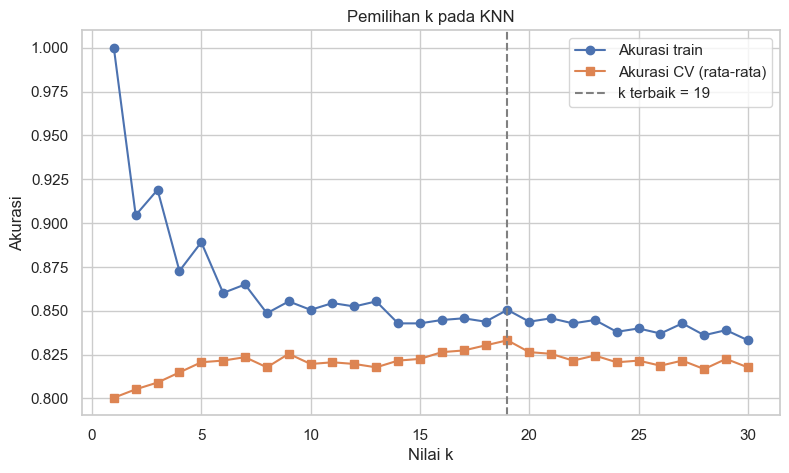

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

daftar_k = range(1, 31)
akurasi_train, akurasi_cv = [], []

for k in daftar_k:
    model_k = Pipeline([("pre", buat_preprocessor()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    model_k.fit(X_train, y_train)
    akurasi_train.append(accuracy_score(y_train, model_k.predict(X_train)))
    akurasi_cv.append(cross_val_score(model_k, X_train, y_train, cv=cv, scoring="accuracy").mean())

k_terbaik = list(daftar_k)[int(np.argmax(akurasi_cv))]
print("k terbaik berdasarkan akurasi CV:", k_terbaik)
print("Akurasi CV pada k tersebut      :", round(max(akurasi_cv), 4))

plt.figure(figsize=(9, 5))
plt.plot(daftar_k, akurasi_train, marker="o", label="Akurasi train")
plt.plot(daftar_k, akurasi_cv, marker="s", label="Akurasi CV (rata-rata)")
plt.axvline(k_terbaik, color="gray", linestyle="--", label=f"k terbaik = {k_terbaik}")
plt.xlabel("Nilai k")
plt.ylabel("Akurasi")
plt.title("Pemilihan k pada KNN")
plt.legend()
plt.show()

### 9.4 Tuning dengan GridSearchCV

In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": list(range(1, 31)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

grid = GridSearchCV(
    Pipeline([("pre", buat_preprocessor()), ("knn", KNeighborsClassifier())]),
    param_grid, cv=cv, scoring="accuracy", n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Parameter terbaik :", grid.best_params_)
print("Akurasi CV terbaik:", round(grid.best_score_, 4))

Parameter terbaik : {'knn__metric': 'manhattan', 'knn__n_neighbors': 12, 'knn__weights': 'distance'}
Akurasi CV terbaik: 0.8496


### 9.5 Evaluasi KNN pada Data Test

In [32]:
from sklearn.metrics import (precision_score, recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

model_knn = grid.best_estimator_
y_pred = model_knn.predict(X_test)

hasil = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (populer)": precision_score(y_test, y_pred),
    "Recall (populer)": recall_score(y_test, y_pred),
    "F1-score (populer)": f1_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
}
pd.DataFrame(hasil, index=["Nilai"]).T.round(4)

,Nilai
Accuracy,0.8500
Precision (populer),0.8649
Recall (populer),0.4848
F1-score (populer),0.6214
Balanced accuracy,0.7295


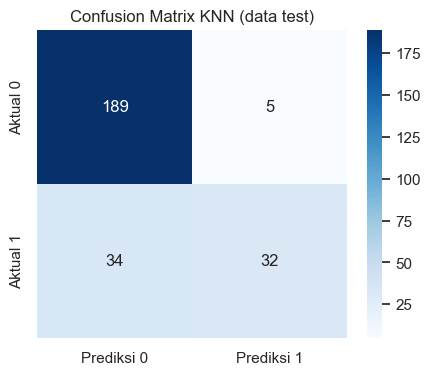

               precision    recall  f1-score   support

tidak populer       0.85      0.97      0.91       194
      populer       0.86      0.48      0.62        66

     accuracy                           0.85       260
    macro avg       0.86      0.73      0.76       260
 weighted avg       0.85      0.85      0.83       260



In [33]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prediksi 0", "Prediksi 1"], yticklabels=["Aktual 0", "Aktual 1"])
plt.title("Confusion Matrix KNN (data test)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["tidak populer", "populer"]))

### 9.6 Analisis Overfitting / Underfitting

In [34]:
akurasi_train_final = accuracy_score(y_train, model_knn.predict(X_train))
akurasi_test_final = accuracy_score(y_test, y_pred)

print(pd.DataFrame({"Akurasi": [akurasi_train_final, grid.best_score_, akurasi_test_final]},
                   index=["Train", "Cross-validation (train)", "Test"]).round(4))
print(f"\nSelisih akurasi train - test: {akurasi_train_final - akurasi_test_final:.4f}")

                          Akurasi
Train                      1.0000
Cross-validation (train)   0.8496
Test                       0.8500

Selisih akurasi train - test: 0.1500


### 9.7 Pembanding: Random Forest dan Faktor Penentu Popularitas

Random Forest dipakai sebagai pembanding, dan **feature importance**-nya menunjukkan faktor yang paling berpengaruh terhadap popularitas video.

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([("pre", buat_preprocessor()),
               ("rf", RandomForestClassifier(n_estimators=300, random_state=42))])
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

pembanding = pd.DataFrame({
    "KNN (tuning)": [accuracy_score(y_test, y_pred), f1_score(y_test, y_pred),
                     recall_score(y_test, y_pred), precision_score(y_test, y_pred)],
    "Random Forest": [accuracy_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf),
                      recall_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf)],
}, index=["Accuracy", "F1 (populer)", "Recall (populer)", "Precision (populer)"])
print("Akurasi train Random Forest:", round(accuracy_score(y_train, rf.predict(X_train)), 4))
pembanding.round(4)

Akurasi train Random Forest: 1.0


,KNN (tuning),Random Forest
Accuracy,0.8500,0.8846
F1 (populer),0.6214,0.7500
Recall (populer),0.4848,0.6818
Precision (populer),0.8649,0.8333


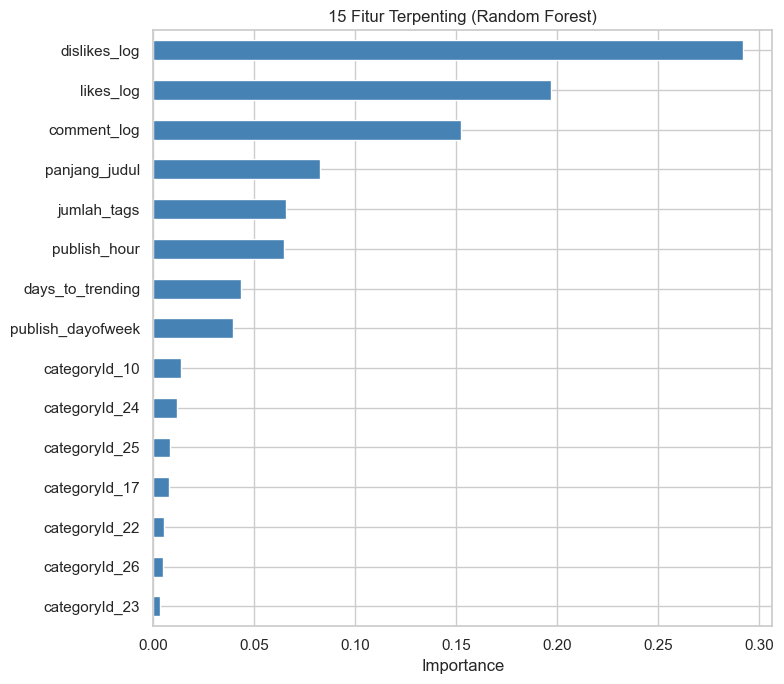

dislikes_log         0.2918
likes_log            0.1967
comment_log          0.1524
panjang_judul        0.0824
jumlah_tags          0.0657
publish_hour         0.0645
days_to_trending     0.0436
publish_dayofweek    0.0393
categoryId_10        0.0135
categoryId_24        0.0116
dtype: float64

In [36]:
nama_fitur = rf.named_steps["pre"].get_feature_names_out()
nama_fitur = [n.split("__", 1)[1] for n in nama_fitur]
pentingnya = pd.Series(rf.named_steps["rf"].feature_importances_, index=nama_fitur).sort_values()

plt.figure(figsize=(8, 7))
pentingnya.tail(15).plot(kind="barh", color="steelblue")
plt.title("15 Fitur Terpenting (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

pentingnya.sort_values(ascending=False).head(10).round(4)

### 9.8 Ekspor Data Split ke CSV

In [37]:
file_csv = {
    "youtube_train_raw.csv": train_raw,
    "youtube_test_raw.csv": test_raw,
    "youtube_train_clean.csv": train_clean,
    "youtube_test_clean.csv": test_clean,
}

for nama_file, data in file_csv.items():
    data.to_csv(nama_file, index=False)

rekap = []
for nama_file in file_csv:
    cek = pd.read_csv(nama_file)
    rekap.append({"File": nama_file, "Jumlah baris": cek.shape[0], "Jumlah kolom": cek.shape[1]})
pd.DataFrame(rekap)

,File,Jumlah baris,Jumlah kolom
0,youtube_train_raw.csv,1037,16
1,youtube_test_raw.csv,260,16
2,youtube_train_clean.csv,1037,24
3,youtube_test_clean.csv,260,24


### 9.9 Kesimpulan

**Video paling banyak views di trending Indonesia:**
1. BLACKPINK - 'Lovesick Girls' M/V: **201,9 juta** views (3 hari trending)
2. BTS - 'Life Goes On' Official MV: **187,0 juta** views (22 hari trending)
3. TWICE - I CAN'T STOP ME M/V: **120,0 juta** views (21 hari trending)

Ada **87 video** dengan peak views >= 10 juta. Video yang paling lama bertahan di trending adalah "TANTANGAN MAKANAN ASLI vs MAKANAN COKLAT" (RATATA Indonesian), **26 hari** dengan 32,9 juta views. Channel dengan video trending terbanyak adalah Indonesian Idol (21 video).

**Model KNN** (k = 12, jarak `manhattan`, bobot `distance`, dipilih lewat GridSearchCV):
- Akurasi test 0,85, precision (populer) 0,8649, recall (populer) 0,4848, F1 0,6214, balanced accuracy 0,7295.
- Confusion matrix: dari 66 video populer, 32 terdeteksi dan 34 terlewat. Dari 194 video tidak populer, 189 benar dan 5 salah ditandai populer.
- **Overfitting/underfitting:** akurasi train 1,0 adalah efek `weights="distance"` (setiap titik train adalah tetangga terdekat dirinya sendiri), jadi selisih train - test tidak bisa dijadikan patokan. Akurasi cross-validation (0,8496) dan test (0,85) hampir sama, sehingga model tergolong **good fit**.
- Kelemahan: recall video populer rendah (48%). Model cenderung menebak "tidak populer" karena kelas populer hanya 25%.

**Pembanding Random Forest:** akurasi 0,8846, F1 0,75, recall 0,6818, precision 0,8333. Lebih baik dalam menemukan video populer dibanding KNN.

**Faktor terpenting (Random Forest):** `dislikes_log` (0,29), `likes_log` (0,20), `comment_log` (0,15). Fitur lain masing-masing di bawah 0,09, dan kategori video berpengaruh kecil.

**Catatan:**
- Likes, dislikes, dan komentar adalah **cerminan** popularitas, bukan penyebabnya, jadi hasil ini tidak bisa dibaca sebagai resep membuat video populer.
- Data test hanya 260 video, sehingga hasilnya perkiraan kasar.
- `hari_trending` dihitung dari jumlah tanggal trending dalam data (24 Oktober 2020 - 12 Januari 2021), jadi video yang sudah trending sebelum periode itu tercatat lebih singkat dari kenyataannya.